# Bayesian Portfolio Optimization for Studio Film Strategy
## Exploratory Data Analysis
**STAT 425 · Rice University · Fall 2026**

In [1]:
suppressPackageStartupMessages({
  library(reticulate)
  library(tidyverse)
  library(ggthemes)
})

use_python('/Users/theoauyeung/.venvs/driveline/bin/python', required = TRUE)

options(repr.plot.width = 14, repr.plot.height = 6)

BASE_THEME <- theme_fivethirtyeight() +
  theme(
    axis.title        = element_text(),
    axis.text         = element_text(size = 10),
    panel.background  = element_rect(fill = 'white', color = NA),
    plot.background   = element_rect(fill = 'white', color = NA),
    legend.background = element_rect(fill = 'white', color = NA),
    strip.text        = element_text(size = 12, face = 'bold'),
    plot.title        = element_text(size = 16, face = 'bold')
  )
theme_set(BASE_THEME)

df <- read_csv('../../data/cleaned/movies_clean.csv', show_col_types = FALSE)
cat('Shape:', nrow(df), 'x', ncol(df), '\n')
head(df)

Warning message:
“package ‘reticulate’ was built under R version 4.4.3”


Warning message:
“package ‘dplyr’ was built under R version 4.4.3”


Shape: 3709 x 37 


id,imdb_id,title,year,decade,month,season,budget_adj,revenue_adj,roi,⋯,genre_fantasy,genre_history,genre_horror,genre_music,genre_mystery,genre_romance,genre_sci_fi,genre_thriller,genre_war,genre_western
<dbl>,<chr>,<chr>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
862,tt0114709,Toy Story,1995,1990,10,Awards,48900000,608893074,11.4518011,⋯,0,0,0,0,0,0,0,0,0,0
8844,tt0113497,Jumanji,1995,1990,12,Awards,105950000,428359516,3.0430346,⋯,1,0,0,0,0,0,0,0,0,0
949,tt0113277,Heat,1995,1990,12,Awards,97800000,305522013,2.1239470,⋯,0,0,0,0,0,0,0,1,0,0
9091,tt0114576,Sudden Death,1995,1990,12,Awards,57050000,104890779,0.8385763,⋯,0,0,0,0,0,0,0,1,0,0
710,tt0113189,GoldenEye,1995,1990,11,Awards,94540000,574076275,5.0723109,⋯,0,0,0,0,0,0,0,1,0,0
9087,tt0112346,The American President,1995,1990,11,Awards,101060000,175843578,0.7399919,⋯,0,0,0,0,0,1,0,0,0,0


### Missing Values

In [2]:
df %>%
  summarise(across(everything(), ~ sum(is.na(.)))) %>%
  pivot_longer(everything(), names_to = 'column', values_to = 'missing_n') %>%
  mutate(missing_pct = round(missing_n / nrow(df) * 100, 2)) %>%
  filter(missing_n > 0) %>%
  arrange(desc(missing_pct))

column,missing_n,missing_pct
<chr>,<int>,<dbl>
studio_label,1272,34.29


### Studio Distribution

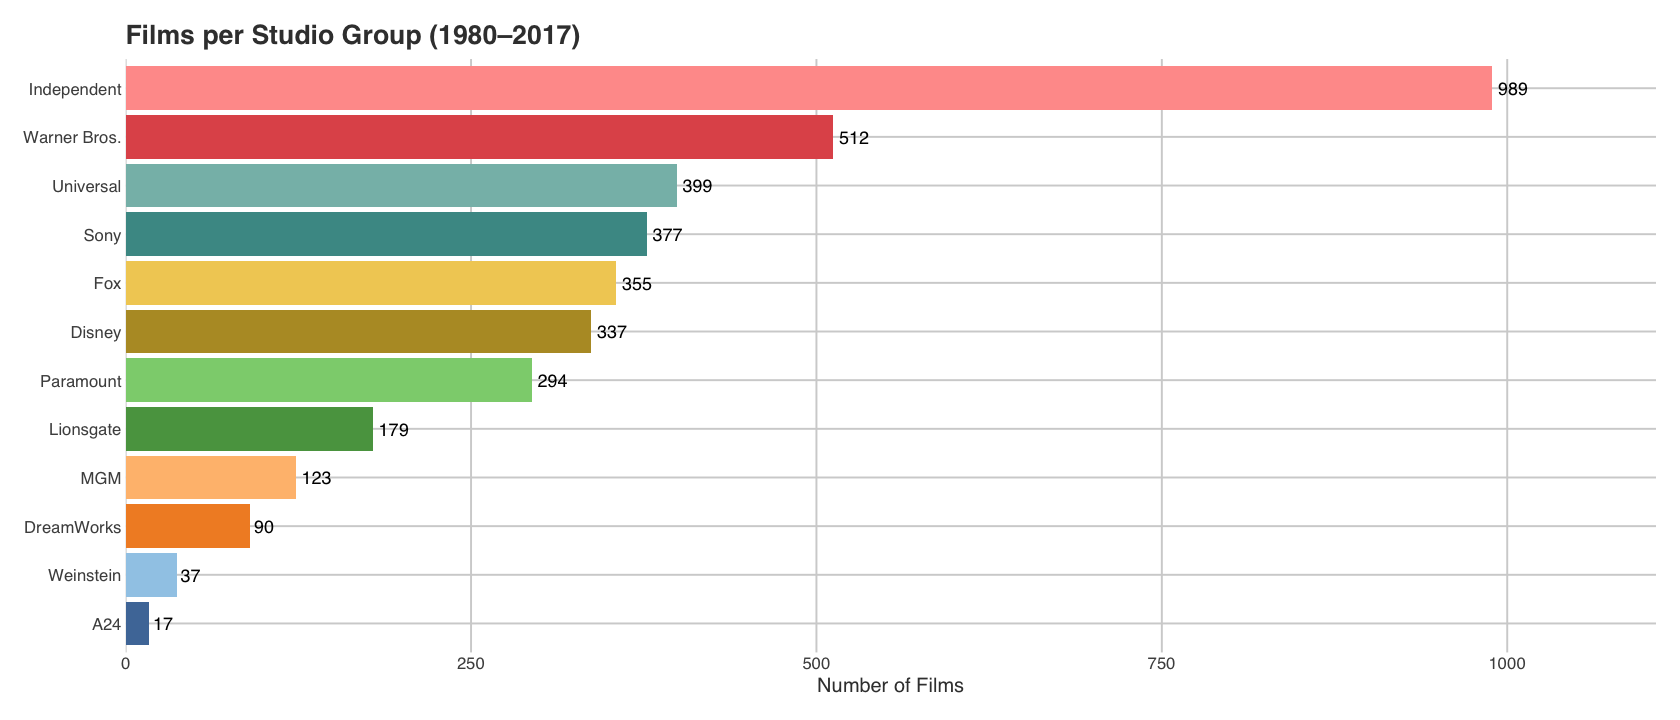

In [3]:
# Films per studio group
df %>%
  count(studio_group, name = 'films') %>%
  arrange(films) %>%
  mutate(studio_group = fct_inorder(studio_group)) %>%
  ggplot(aes(x = films, y = studio_group, fill = studio_group)) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = films), hjust = -0.2, size = 3.8) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_tableau(palette = 'Tableau 20') +
  labs(
    title = 'Films per Studio Group (1980–2017)',
    x = 'Number of Films',
    y = NULL
  )

Warning message in check_pal_n(n, max_n):
“This palette can handle a maximum of 10 values.You have supplied 11.”


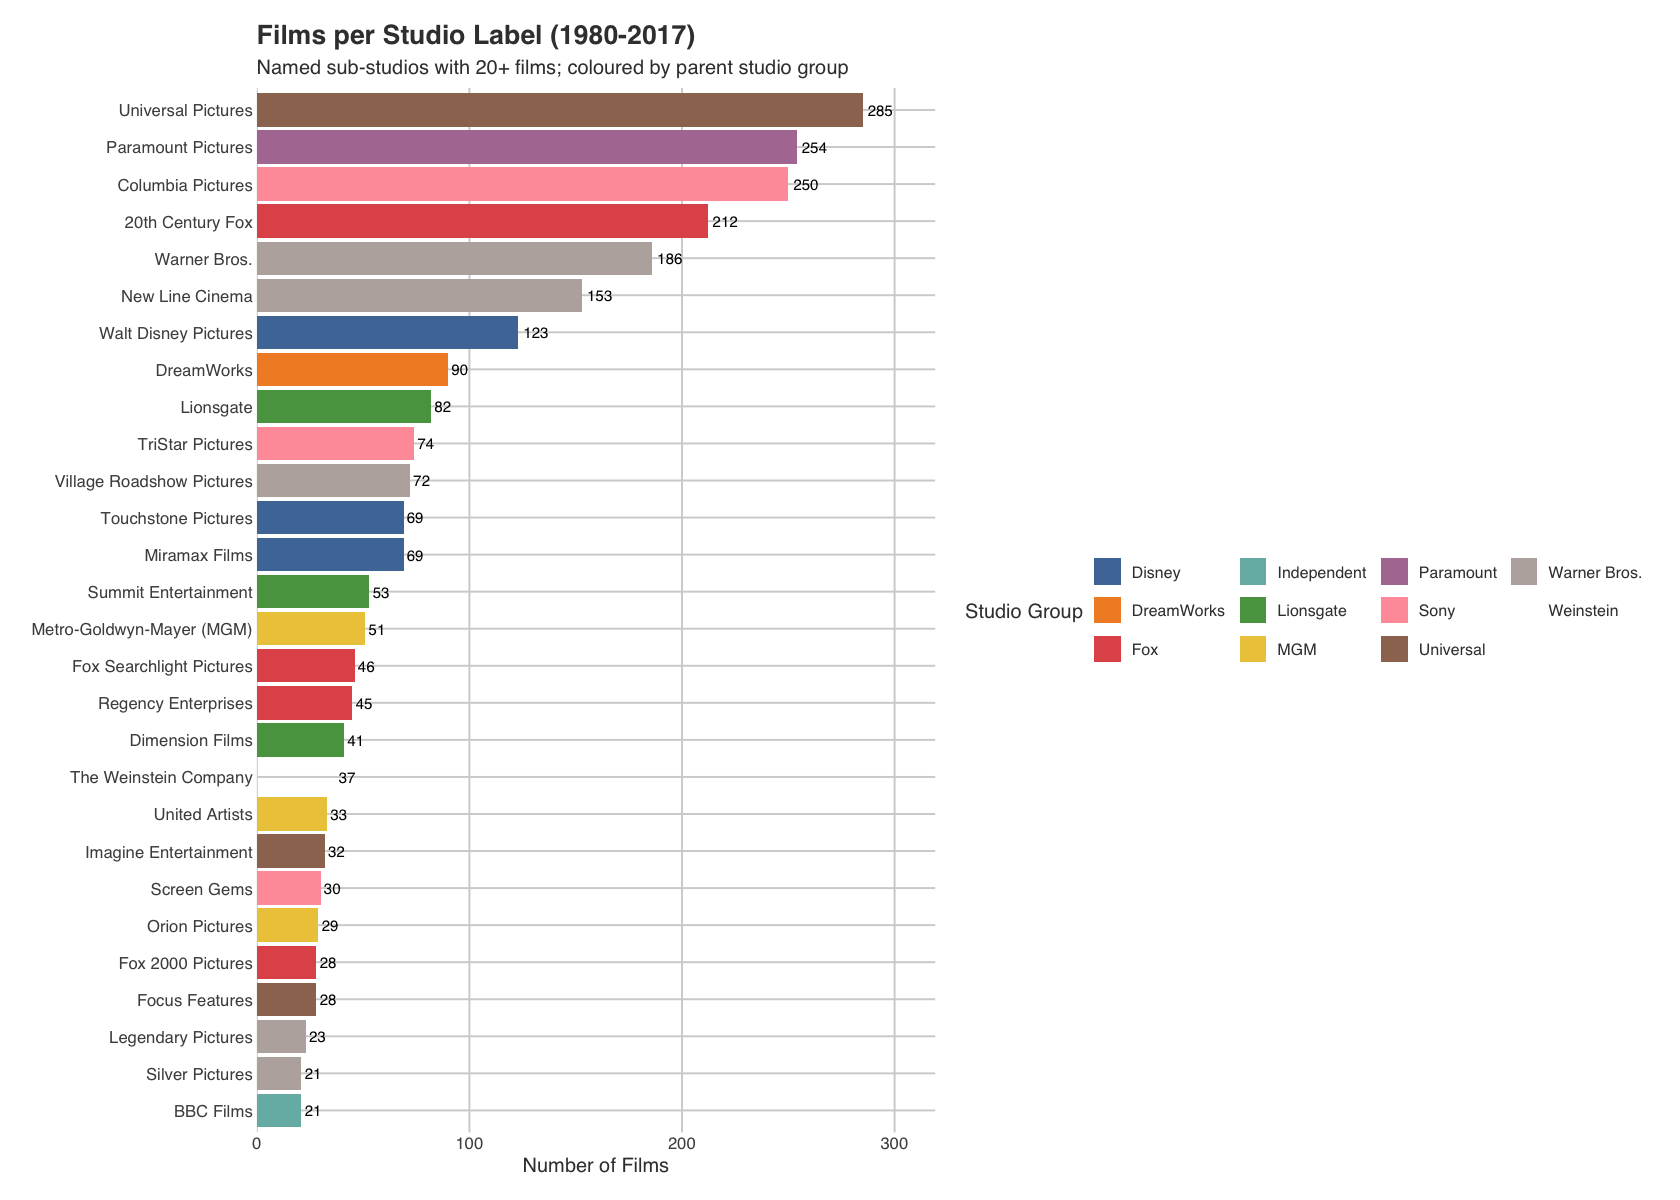

In [4]:
# Films per studio label (sub-studio breakdown) — NAs excluded
options(repr.plot.width = 14, repr.plot.height = 10)

df %>%
  filter(!is.na(studio_label)) %>%
  count(studio_label, studio_group, name = 'films') %>%
  arrange(films) %>%
  mutate(studio_label = fct_inorder(studio_label)) %>%
  ggplot(aes(x = films, y = studio_label, fill = studio_group)) +
  geom_col() +
  geom_text(aes(label = films), hjust = -0.2, size = 3.2) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_tableau(name = 'Studio Group') +
  labs(
    title = 'Films per Studio Label (1980-2017)',
    subtitle = 'Named sub-studios with 20+ films; coloured by parent studio group',
    x = 'Number of Films',
    y = NULL
  ) +
  theme(legend.position = 'right')

### Release Year Distribution

decade,film_count
<dbl>,<int>
1980,394
1990,694
2000,1365
2010,1256


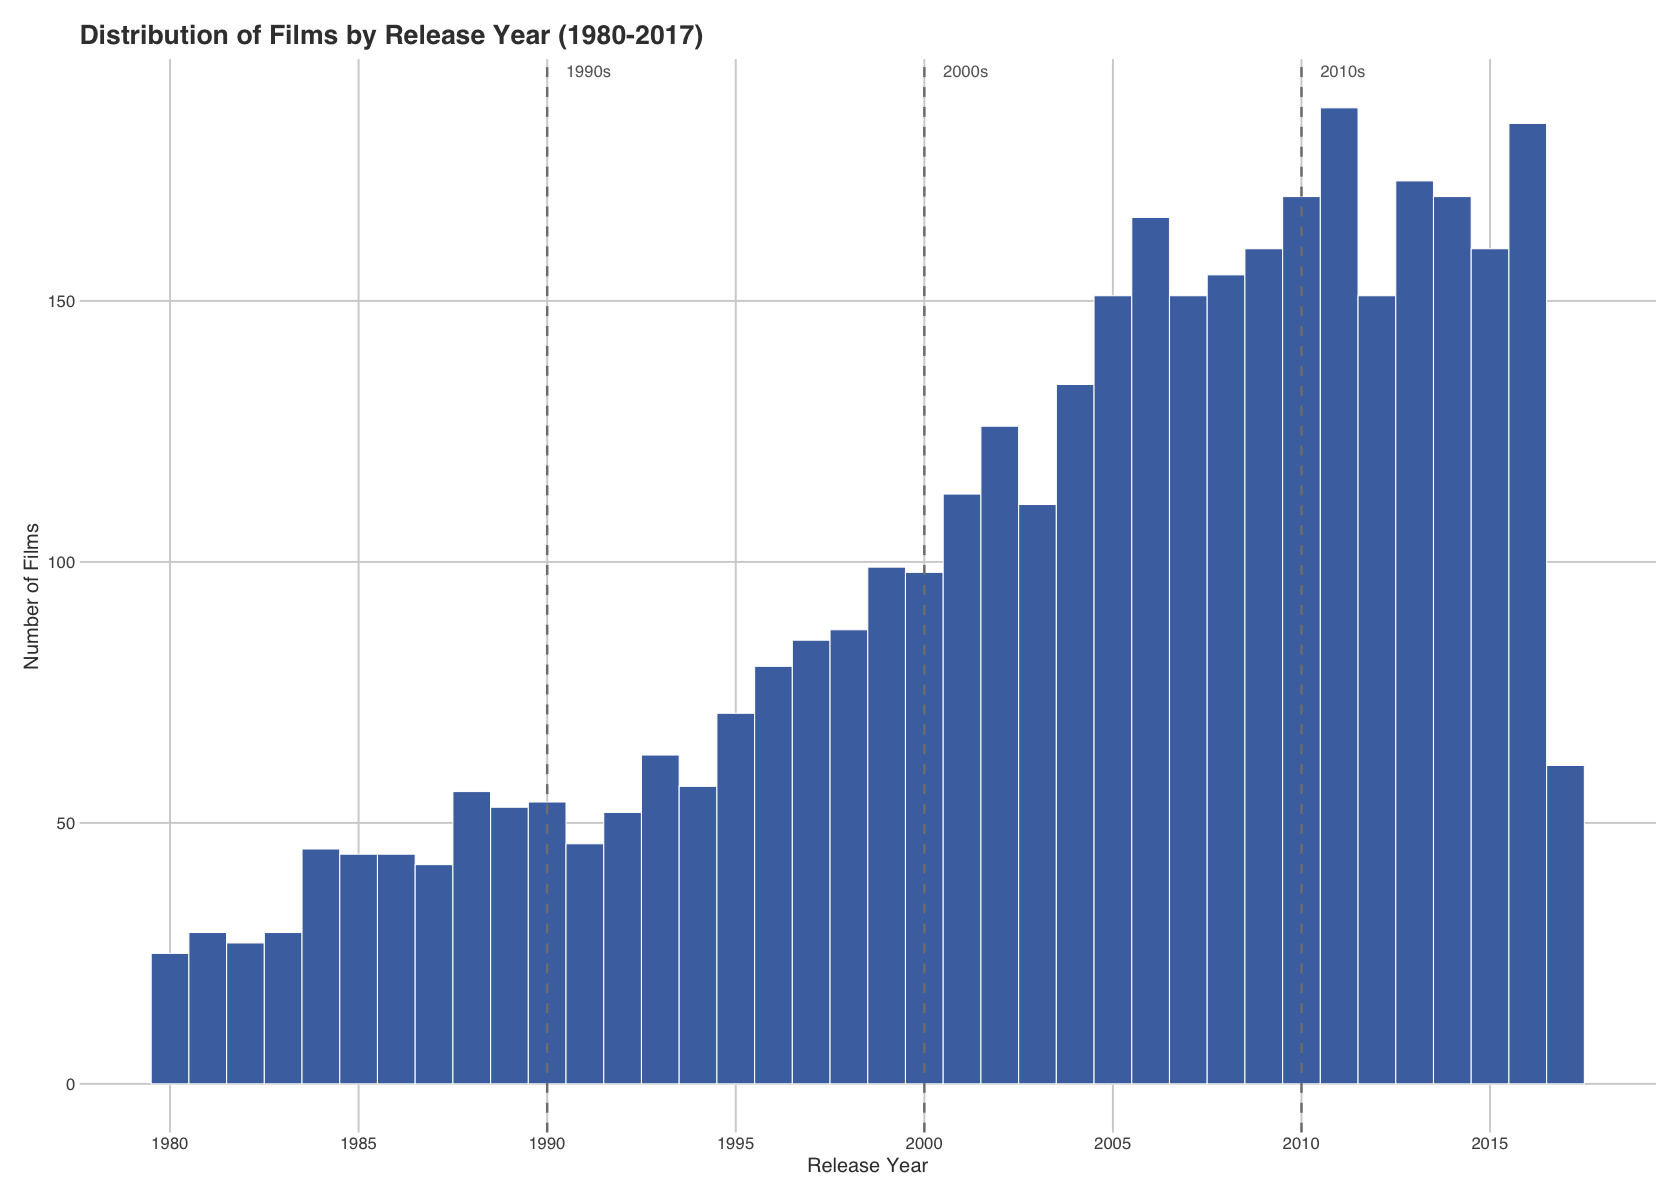

In [5]:
df %>%
  ggplot(aes(x = year)) +
  geom_histogram(binwidth = 1, fill = '#4C72B0', color = 'white', linewidth = 0.3) +
  geom_vline(xintercept = c(1990, 2000, 2010), linetype = 'dashed',
             color = 'grey50', linewidth = 0.7) +
  annotate('text', x = c(1990.5, 2000.5, 2010.5),
           y = Inf, vjust = 1.5, hjust = 0,
           label = c('1990s', '2000s', '2010s'),
           color = 'grey40', size = 3.5) +
  scale_x_continuous(breaks = seq(1980, 2017, by = 5)) +
  labs(
    title = 'Distribution of Films by Release Year (1980-2017)',
    x = 'Release Year',
    y = 'Number of Films'
  )

df %>% count(decade, name = 'film_count') %>% arrange(decade)

## ROI Analysis

### Overall Distribution

Films with ROI < 0 (loss):  985 (26.6%)


Films with ROI > 1 (2x):    1966 (53.0%)


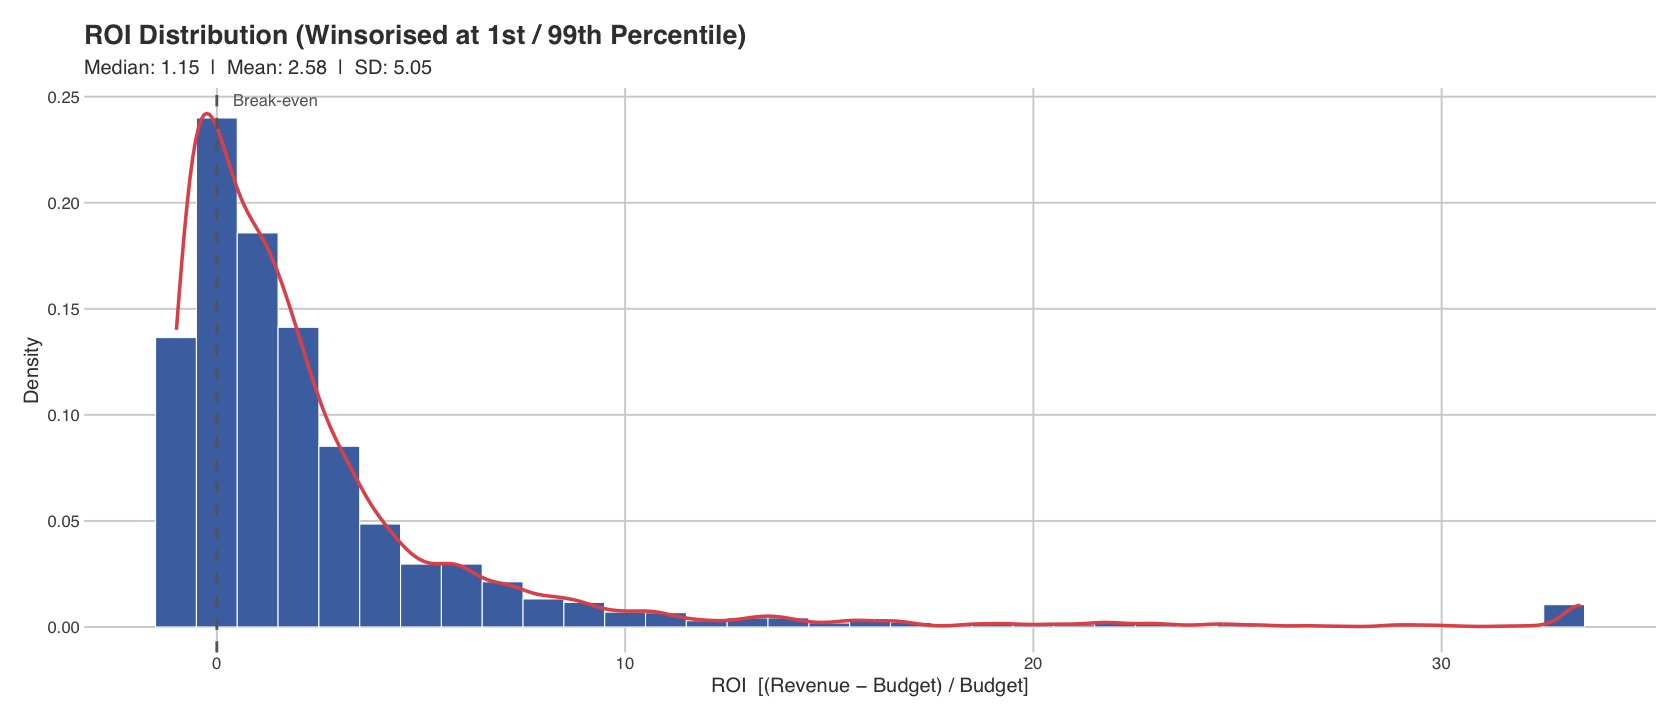

In [6]:
options(repr.plot.width = 14, repr.plot.height = 6)

ggplot(df, aes(x = roi)) +
  geom_histogram(aes(y = after_stat(density)), binwidth = 1,
                 fill = '#4C72B0', color = 'white', linewidth = 0.3) +
  geom_density(color = '#E15759', linewidth = 1) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  annotate('text', x = 0.4, y = Inf, vjust = 1.5, hjust = 0,
           label = 'Break-even', color = 'grey40', size = 3.5) +
  labs(
    title = 'ROI Distribution (Winsorised at 1st / 99th Percentile)',
    subtitle = sprintf('Median: %.2f  |  Mean: %.2f  |  SD: %.2f',
                       median(df$roi), mean(df$roi), sd(df$roi)),
    x = 'ROI  [(Revenue − Budget) / Budget]',
    y = 'Density'
  )

cat(sprintf('Films with ROI < 0 (loss):  %d (%.1f%%)\n',
            sum(df$roi < 0), 100 * mean(df$roi < 0)))
cat(sprintf('Films with ROI > 1 (2x):    %d (%.1f%%)\n',
            sum(df$roi > 1), 100 * mean(df$roi > 1)))

### ROI by Genre

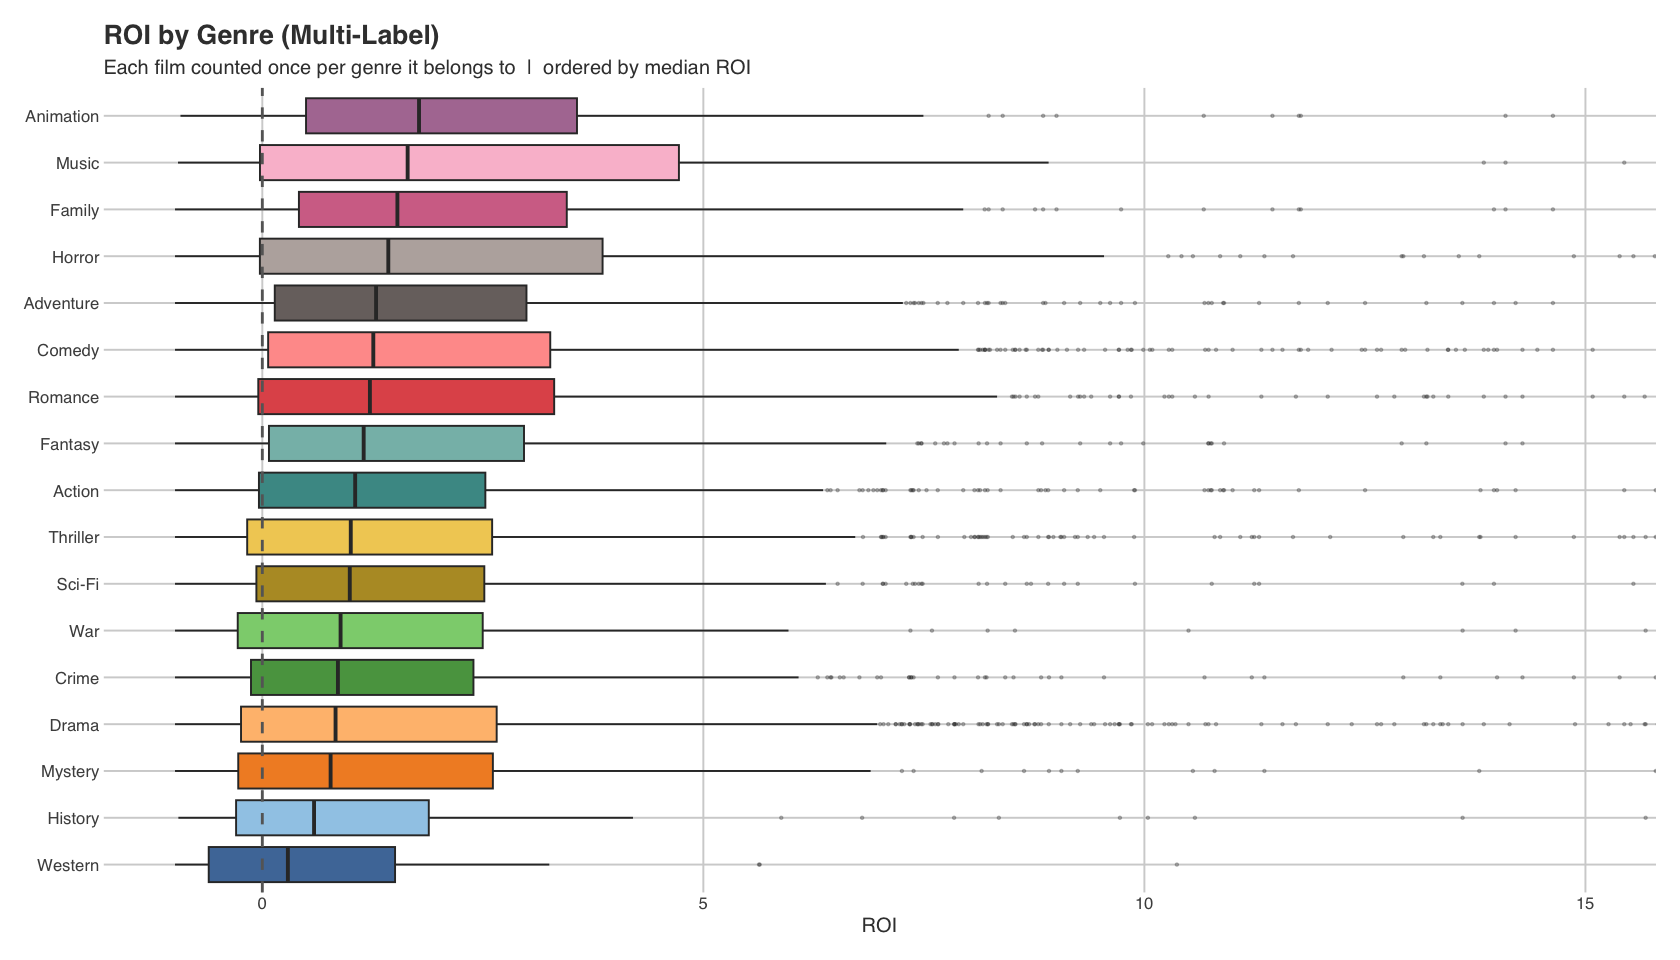

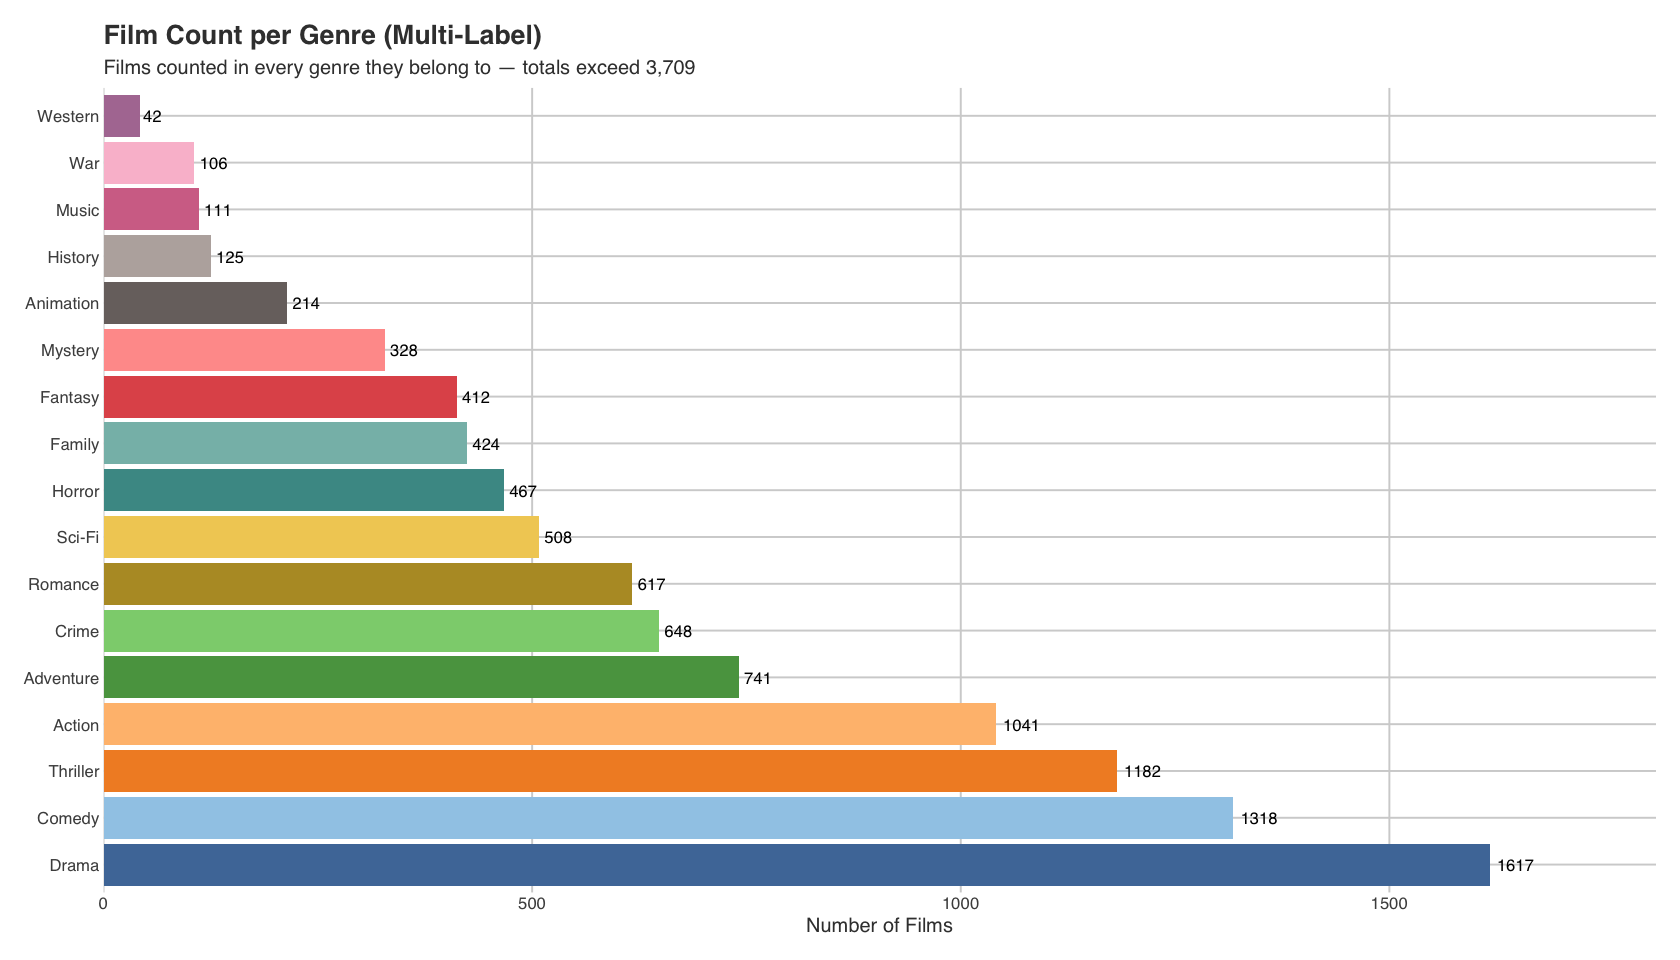

In [7]:
options(repr.plot.width = 14, repr.plot.height = 8)

genre_cols <- c(
  'genre_action','genre_adventure','genre_animation','genre_comedy',
  'genre_crime','genre_drama','genre_family','genre_fantasy',
  'genre_history','genre_horror','genre_music','genre_mystery',
  'genre_romance','genre_sci_fi','genre_thriller','genre_war','genre_western'
)

genre_labels <- c(
  'Action','Adventure','Animation','Comedy','Crime','Drama',
  'Family','Fantasy','History','Horror','Music','Mystery',
  'Romance','Sci-Fi','Thriller','War','Western'
)

# Build long-form data: one row per film × genre it belongs to
genre_long <- purrr::map2_dfr(genre_cols, genre_labels, function(col, label) {
  df %>%
    filter(.data[[col]] == 1) %>%
    mutate(genre = label) %>%
    select(roi, genre)
})

genre_order <- genre_long %>%
  group_by(genre) %>%
  summarise(med_roi = median(roi), n = n(), .groups = 'drop') %>%
  arrange(med_roi) %>%
  pull(genre)

genre_long %>%
  mutate(genre = factor(genre, levels = genre_order)) %>%
  ggplot(aes(x = roi, y = genre, fill = genre)) +
  geom_boxplot(outlier.size = 0.6, outlier.alpha = 0.3, show.legend = FALSE) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  coord_cartesian(xlim = c(-1, 15)) +
  scale_fill_tableau(palette = 'Tableau 20') +
  labs(
    title = 'ROI by Genre (Multi-Label)',
    subtitle = 'Each film counted once per genre it belongs to  |  ordered by median ROI',
    x = 'ROI',
    y = NULL
  )

# Film counts per genre
genre_long %>%
  count(genre, name = 'films') %>%
  arrange(desc(films)) %>%
  mutate(genre = factor(genre, levels = genre)) %>%
  ggplot(aes(x = films, y = genre, fill = genre)) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = films), hjust = -0.2, size = 3.5) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.12))) +
  scale_fill_tableau(palette = 'Tableau 20') +
  labs(
    title = 'Film Count per Genre (Multi-Label)',
    subtitle = 'Films counted in every genre they belong to — totals exceed 3,709',
    x = 'Number of Films',
    y = NULL
  )

### ROI by Budget Tier

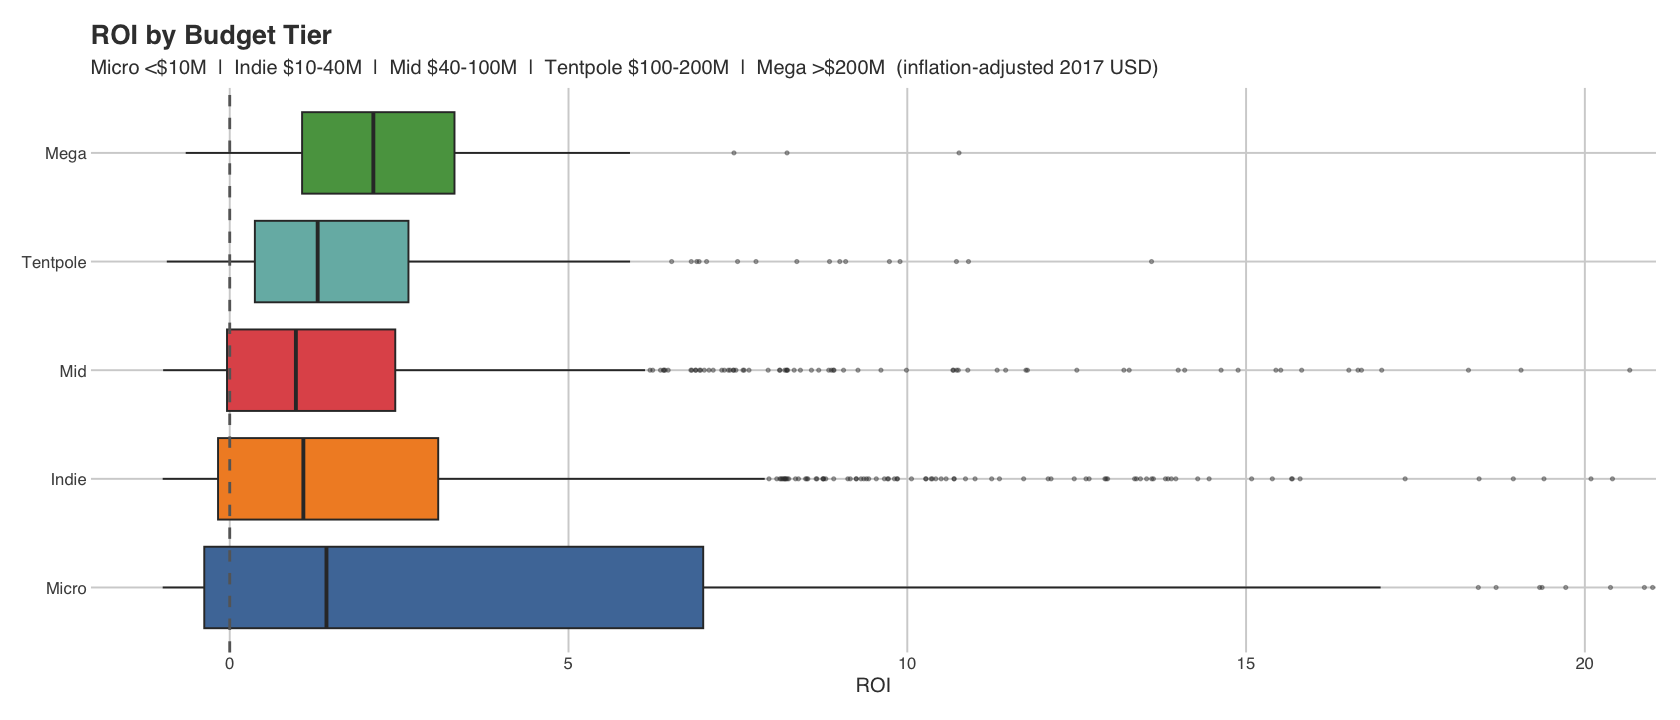

In [8]:
options(repr.plot.width = 14, repr.plot.height = 6)

tier_levels <- c('Micro', 'Indie', 'Mid', 'Tentpole', 'Mega')

df %>%
  mutate(budget_tier = factor(budget_tier, levels = tier_levels)) %>%
  ggplot(aes(x = roi, y = budget_tier, fill = budget_tier)) +
  geom_boxplot(outlier.size = 0.8, outlier.alpha = 0.4, show.legend = FALSE) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  coord_cartesian(xlim = c(-1, 20)) +
  scale_fill_tableau() +
  labs(
    title = 'ROI by Budget Tier',
    subtitle = 'Micro <$10M  |  Indie $10-40M  |  Mid $40-100M  |  Tentpole $100-200M  |  Mega >$200M  (inflation-adjusted 2017 USD)',
    x = 'ROI',
    y = NULL
  )

### ROI by IP Type

ip_type,n,median_roi,mean_roi,pct_loss
<chr>,<int>,<dbl>,<dbl>,<dbl>
Franchise,987,2.56,4.45,7.8
Adaptation,218,0.86,1.70,30.3
Original,2454,0.65,1.94,33.8
Remake,50,0.65,0.93,26.0


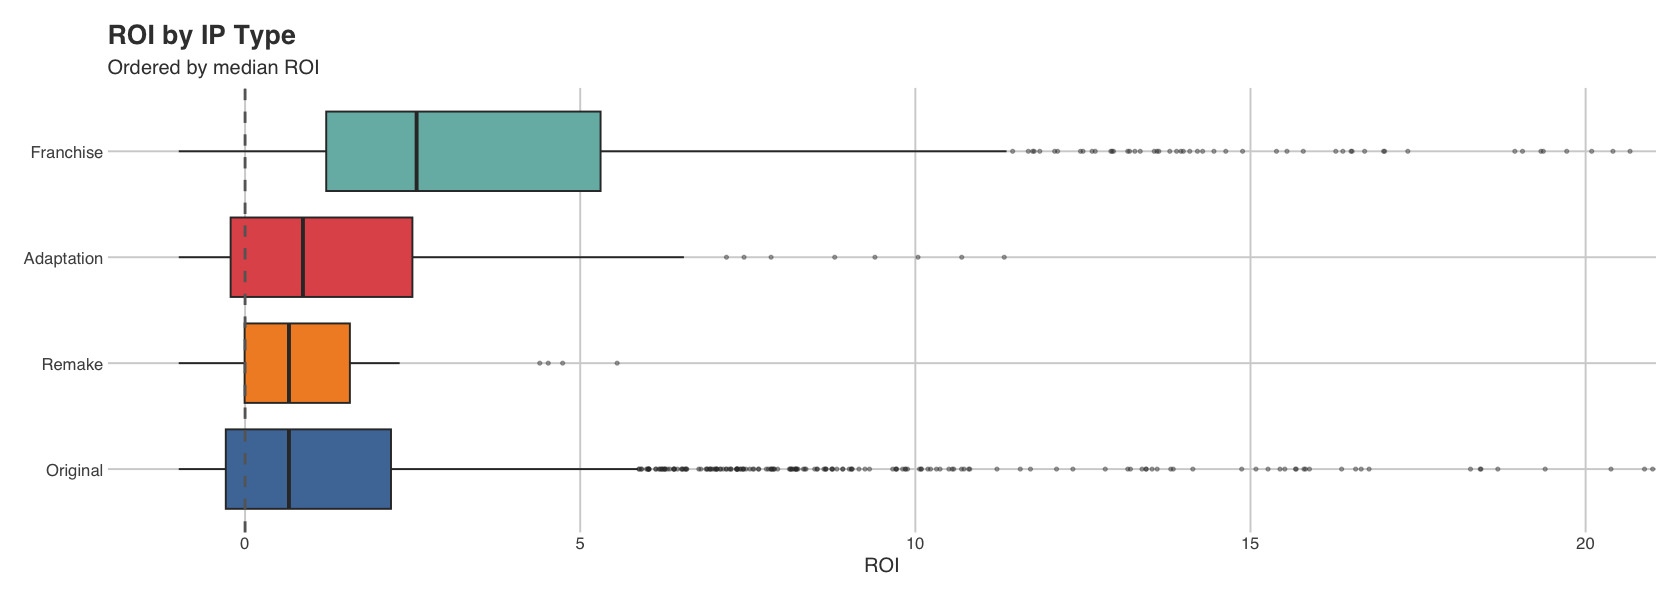

In [9]:
options(repr.plot.width = 14, repr.plot.height = 5)

ip_order <- df %>%
  group_by(ip_type) %>%
  summarise(med_roi = median(roi), .groups = 'drop') %>%
  arrange(med_roi) %>%
  pull(ip_type)

df %>%
  mutate(ip_type = factor(ip_type, levels = ip_order)) %>%
  ggplot(aes(x = roi, y = ip_type, fill = ip_type)) +
  geom_boxplot(outlier.size = 0.8, outlier.alpha = 0.4, show.legend = FALSE) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  coord_cartesian(xlim = c(-1, 20)) +
  scale_fill_tableau() +
  labs(
    title = 'ROI by IP Type',
    subtitle = 'Ordered by median ROI',
    x = 'ROI',
    y = NULL
  )

df %>%
  group_by(ip_type) %>%
  summarise(n = n(), median_roi = round(median(roi), 2),
            mean_roi = round(mean(roi), 2), pct_loss = round(100 * mean(roi < 0), 1),
            .groups = 'drop') %>%
  arrange(desc(median_roi))

### ROI by Studio Group

Warning message in check_pal_n(n, max_n):
“This palette can handle a maximum of 10 values.You have supplied 12.”


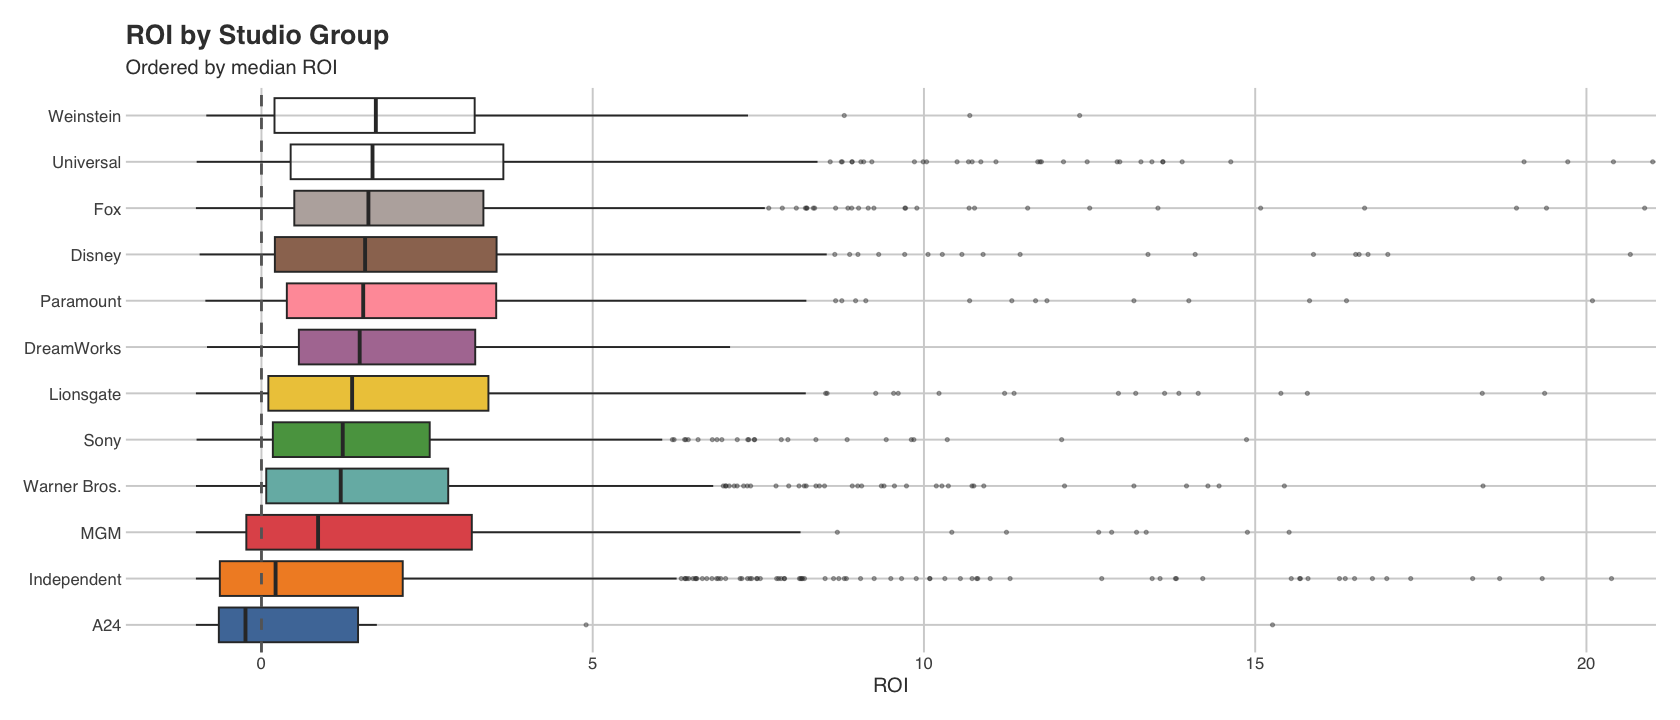

In [10]:
options(repr.plot.width = 14, repr.plot.height = 6)

studio_order <- df %>%
  group_by(studio_group) %>%
  summarise(med_roi = median(roi), .groups = 'drop') %>%
  arrange(med_roi) %>%
  pull(studio_group)

df %>%
  mutate(studio_group = factor(studio_group, levels = studio_order)) %>%
  ggplot(aes(x = roi, y = studio_group, fill = studio_group)) +
  geom_boxplot(outlier.size = 0.8, outlier.alpha = 0.4, show.legend = FALSE) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  coord_cartesian(xlim = c(-1, 20)) +
  scale_fill_tableau() +
  labs(
    title = 'ROI by Studio Group',
    subtitle = 'Ordered by median ROI',
    x = 'ROI',
    y = NULL
  )

### ROI by Decade

`geom_smooth()` using formula = 'y ~ x'


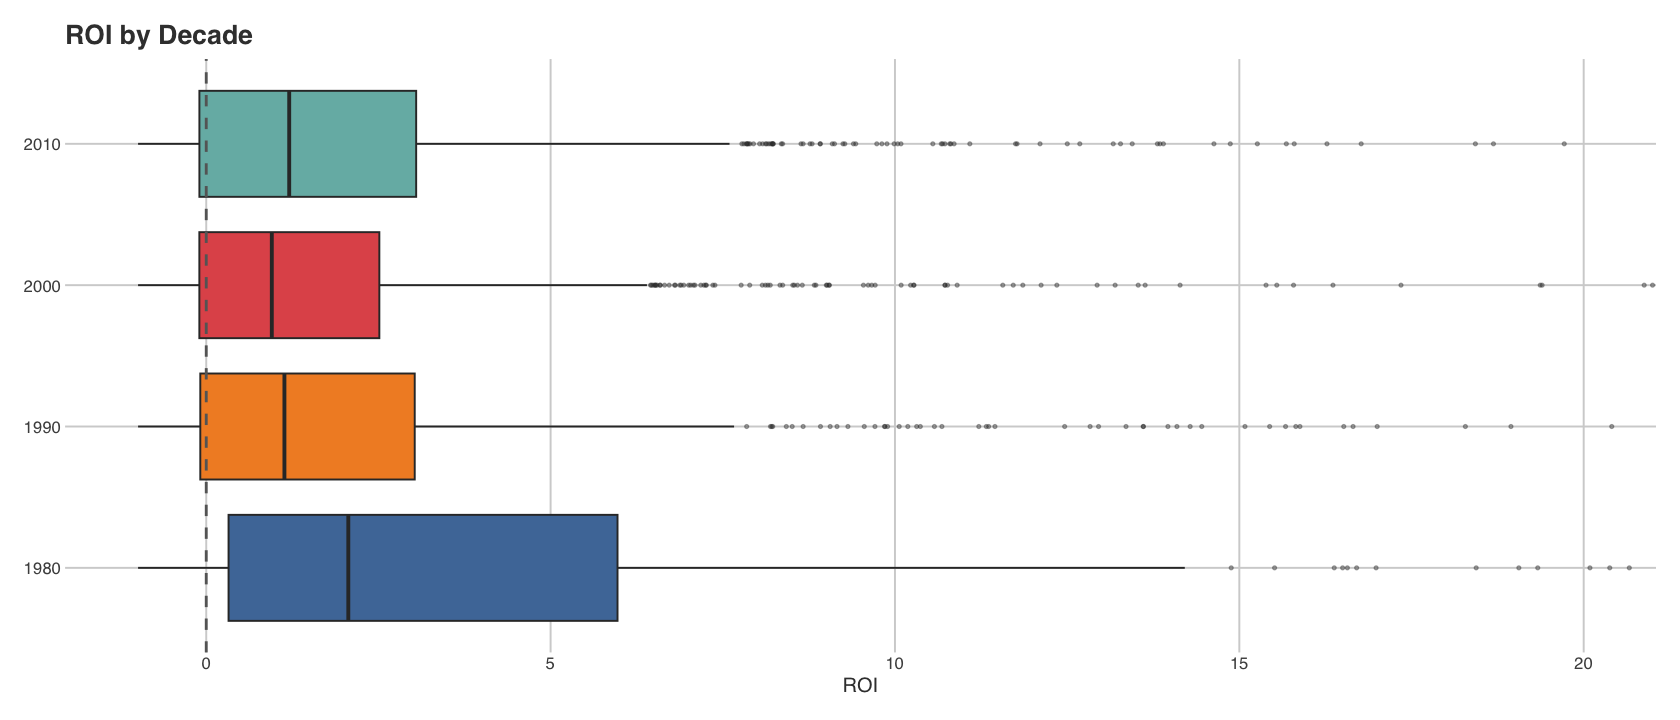

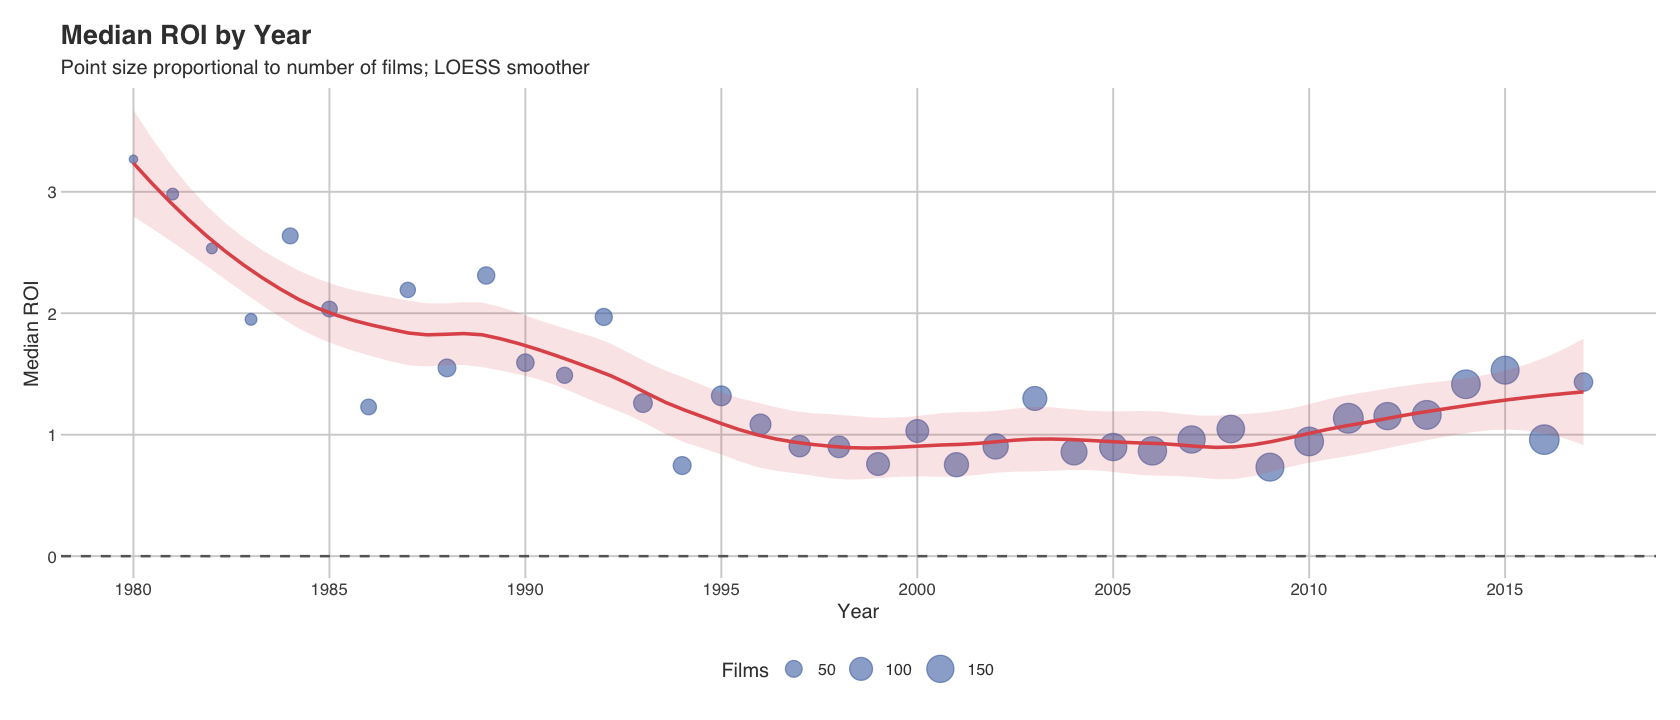

In [11]:
options(repr.plot.width = 14, repr.plot.height = 6)

df %>%
  mutate(decade = factor(decade)) %>%
  ggplot(aes(x = roi, y = decade, fill = decade)) +
  geom_boxplot(outlier.size = 0.8, outlier.alpha = 0.4, show.legend = FALSE) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.8) +
  coord_cartesian(xlim = c(-1, 20)) +
  scale_fill_tableau() +
  labs(
    title = 'ROI by Decade',
    x = 'ROI',
    y = NULL
  )

# Median ROI per year (trend line)
df %>%
  group_by(year) %>%
  summarise(med_roi = median(roi), n = n(), .groups = 'drop') %>%
  ggplot(aes(x = year, y = med_roi)) +
  geom_point(aes(size = n), alpha = 0.6, color = '#4C72B0') +
  geom_smooth(method = 'loess', span = 0.4, color = '#E15759',
              fill = '#E15759', alpha = 0.15, linewidth = 1) +
  geom_hline(yintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.7) +
  scale_x_continuous(breaks = seq(1980, 2017, by = 5)) +
  scale_size_continuous(name = 'Films', range = c(2, 8)) +
  labs(
    title = 'Median ROI by Year',
    subtitle = 'Point size proportional to number of films; LOESS smoother',
    x = 'Year',
    y = 'Median ROI'
  )

### Genre × Season Heatmap (Mean ROI, Multi-Label)

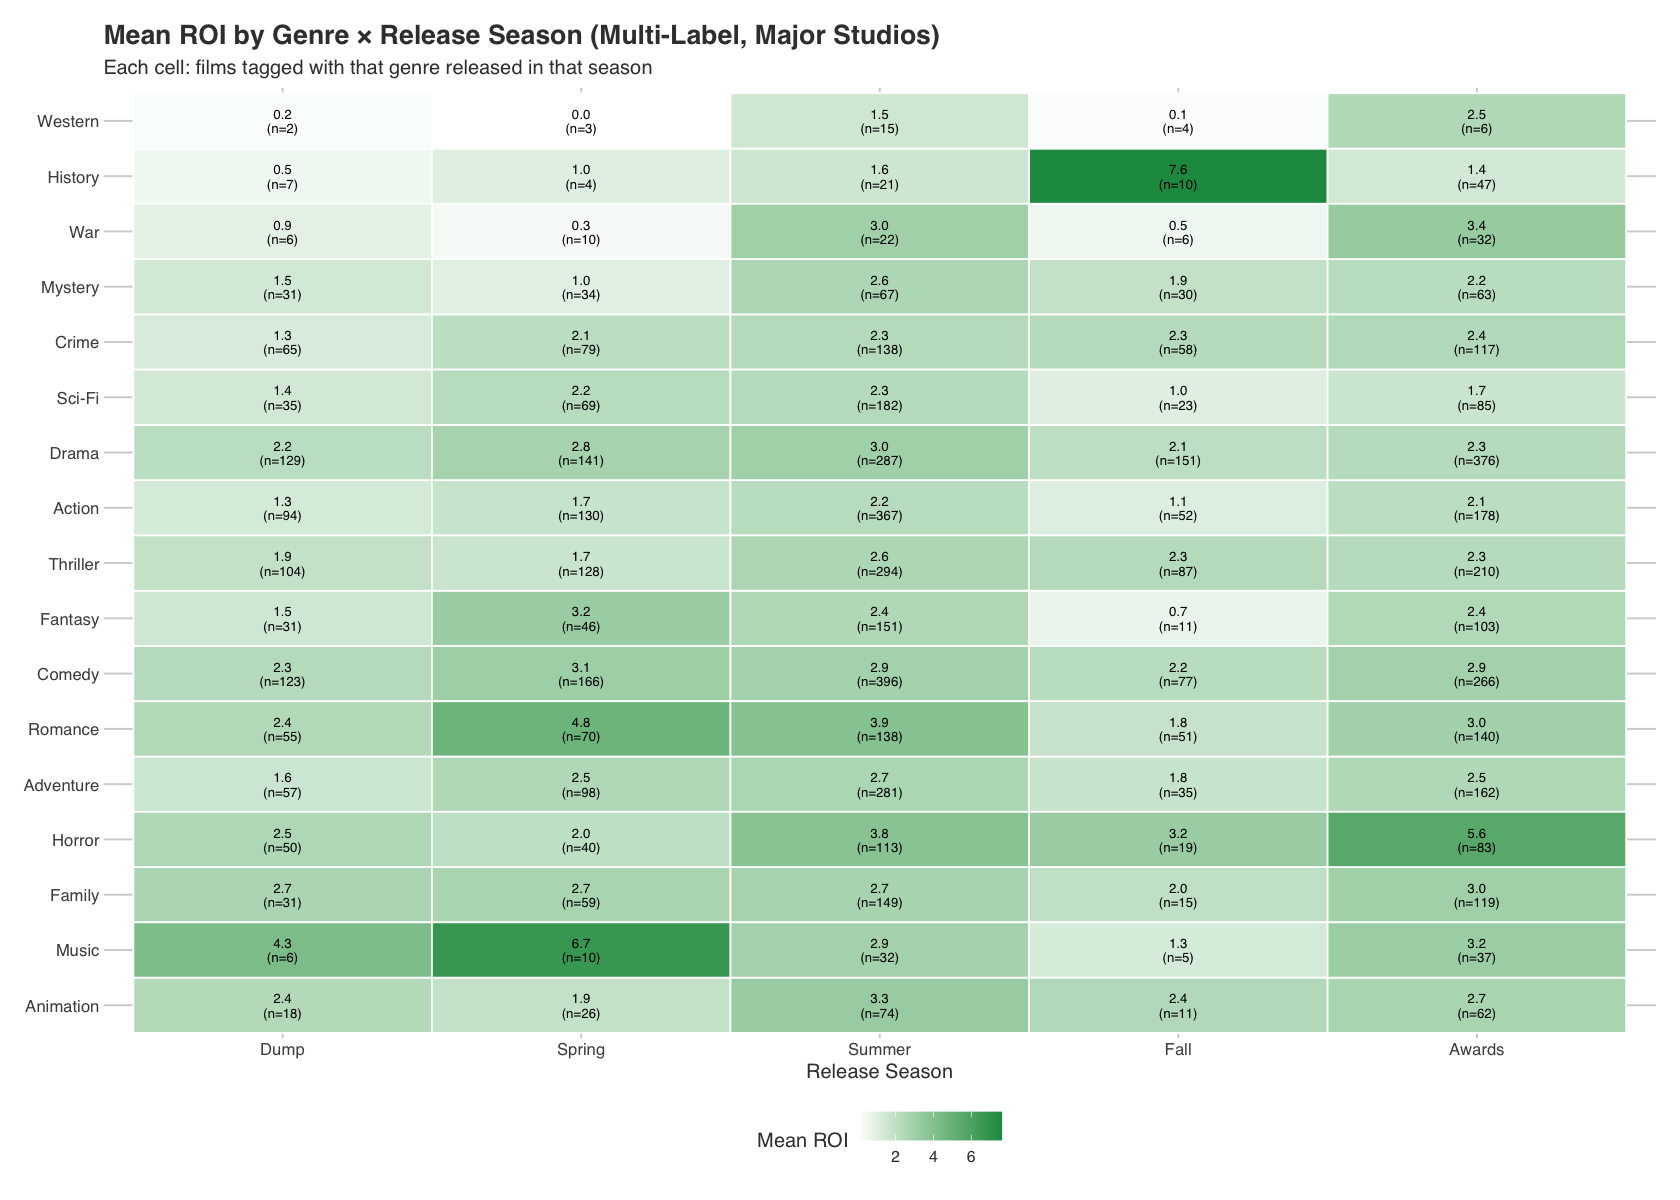

In [12]:
options(repr.plot.width = 14, repr.plot.height = 10)

genre_cols <- c(
  'genre_action','genre_adventure','genre_animation','genre_comedy',
  'genre_crime','genre_drama','genre_family','genre_fantasy',
  'genre_history','genre_horror','genre_music','genre_mystery',
  'genre_romance','genre_sci_fi','genre_thriller','genre_war','genre_western'
)
genre_labels <- c(
  'Action','Adventure','Animation','Comedy','Crime','Drama',
  'Family','Fantasy','History','Horror','Music','Mystery',
  'Romance','Sci-Fi','Thriller','War','Western'
)
season_levels <- c('Dump','Spring','Summer','Fall','Awards')

heat_data <- purrr::map2_dfr(genre_cols, genre_labels, function(col, label) {
  df %>%
    filter(.data[[col]] == 1, studio_group != 'Independent') %>%
    mutate(season = factor(season, levels = season_levels)) %>%
    group_by(season) %>%
    summarise(mean_roi = mean(roi), n = n(), .groups = 'drop') %>%
    mutate(genre = label)
})

genre_order_heat <- purrr::map2_dfr(genre_cols, genre_labels, function(col, label) {
  df %>%
    filter(.data[[col]] == 1, studio_group != 'Independent') %>%
    summarise(med = median(roi), .groups = 'drop') %>%
    mutate(genre = label)
}) %>%
  arrange(desc(med)) %>%
  pull(genre)

heat_data %>%
  mutate(genre = factor(genre, levels = genre_order_heat)) %>%
  ggplot(aes(x = season, y = genre, fill = mean_roi)) +
  geom_tile(color = 'white', linewidth = 0.5) +
  geom_text(aes(label = sprintf('%.1f\n(n=%d)', mean_roi, n)),
            size = 2.8, lineheight = 0.9) +
  scale_fill_gradient2(
    low = '#d73027', mid = 'white', high = '#1a9850',
    midpoint = 0, name = 'Mean ROI'
  ) +
  labs(
    title = 'Mean ROI by Genre × Release Season (Multi-Label, Major Studios)',
    subtitle = 'Each cell: films tagged with that genre released in that season',
    x = 'Release Season', y = NULL
  ) +
  theme(axis.text.x = element_text(angle = 0))

### Budget vs ROI (Continuous)

`geom_smooth()` using formula = 'y ~ x'


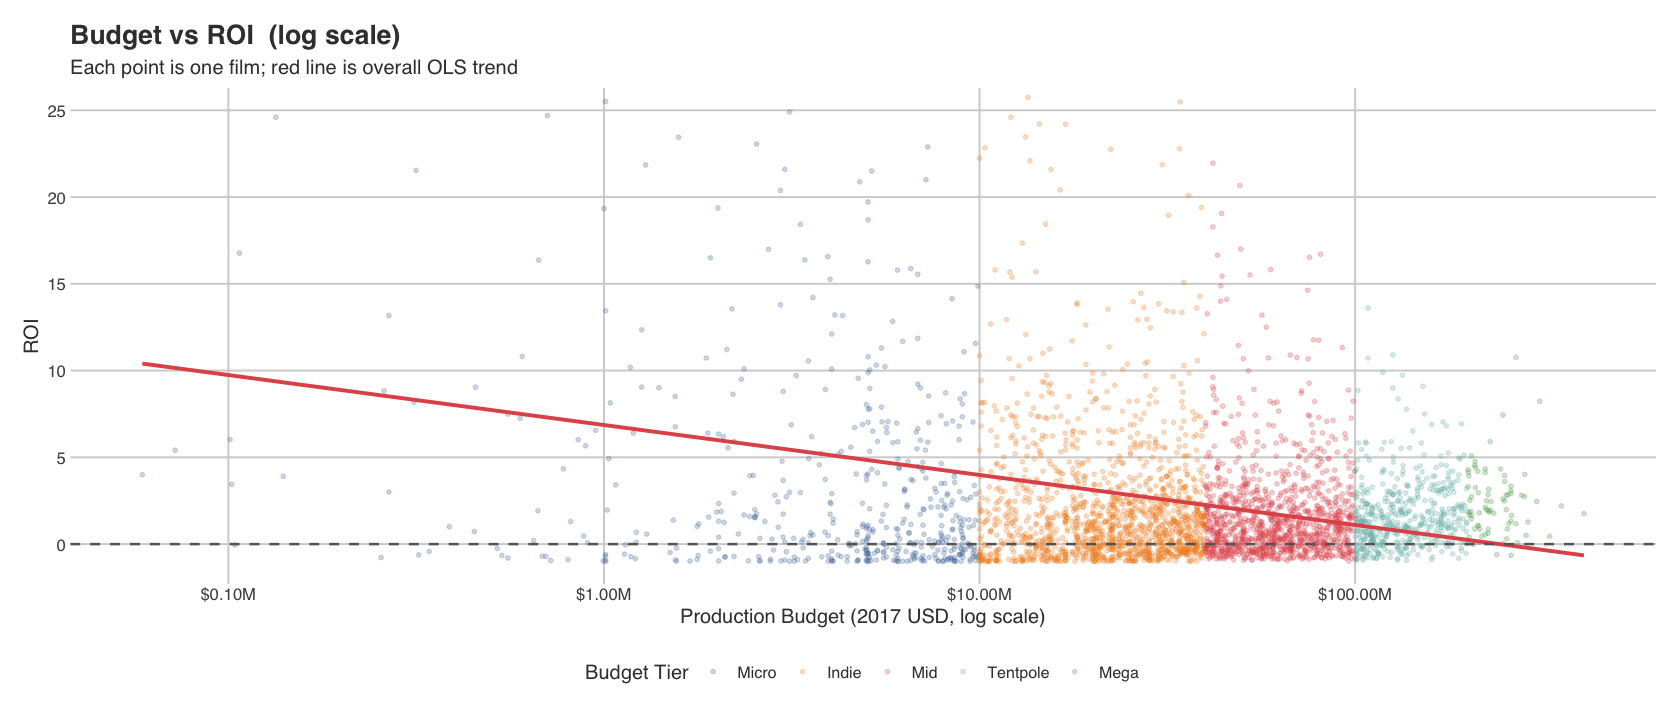

In [13]:
options(repr.plot.width = 14, repr.plot.height = 6)

tier_levels <- c('Micro', 'Indie', 'Mid', 'Tentpole', 'Mega')

df %>%
  mutate(budget_tier = factor(budget_tier, levels = tier_levels)) %>%
  ggplot(aes(x = budget_adj / 1e6, y = roi, color = budget_tier)) +
  geom_point(alpha = 0.25, size = 0.9) +
  geom_smooth(method = 'lm', se = FALSE, linewidth = 1.1,
              aes(group = 1), color = '#E15759') +
  geom_hline(yintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.7) +
  scale_x_log10(labels = scales::label_dollar(suffix = 'M')) +
  coord_cartesian(ylim = c(-1, 25)) +
  scale_color_tableau(name = 'Budget Tier') +
  labs(
    title = 'Budget vs ROI  (log scale)',
    subtitle = 'Each point is one film; red line is overall OLS trend',
    x = 'Production Budget (2017 USD, log scale)',
    y = 'ROI'
  )

### Target Variable Diagnostic: sqrt(ROI + 1) on Major Studios

Full dataset: 3709 films


Major studios only: 2720 films


n,roi_mean,roi_sd,roi_skew,sqrt_mean,sqrt_sd,sqrt_skew
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
2720,2.72,4.7,3.79,1.7,0.91,1.64


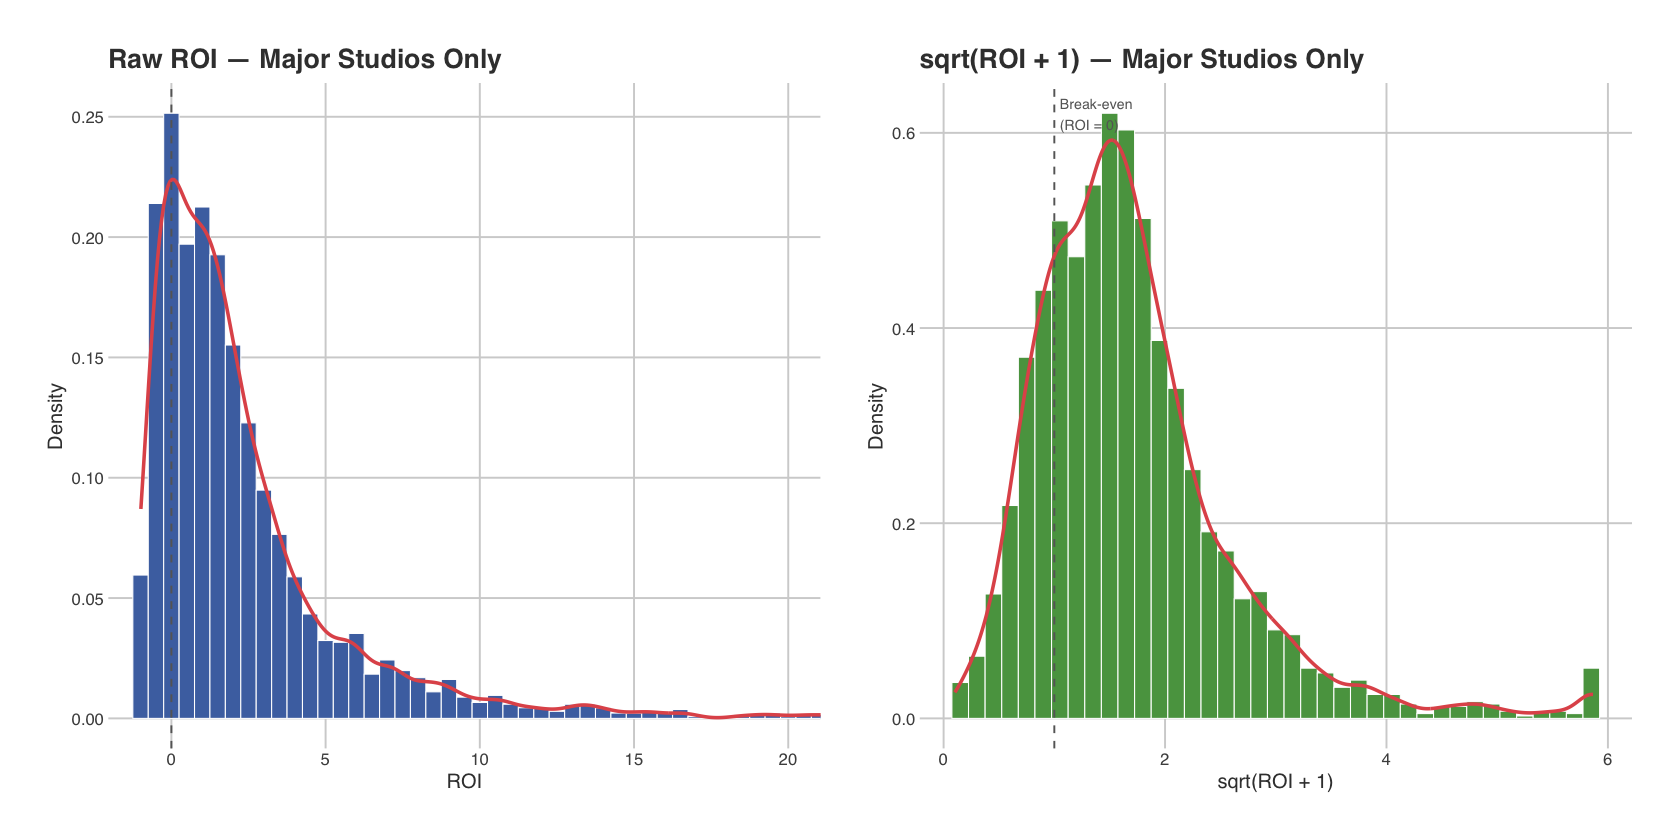

In [14]:
options(repr.plot.width = 14, repr.plot.height = 7)

df_major <- df %>% filter(studio_group != 'Independent')

cat(sprintf('Full dataset: %d films\n', nrow(df)))
cat(sprintf('Major studios only: %d films\n', nrow(df_major)))

# Side-by-side: raw ROI vs sqrt(ROI + 1) on major studios
p1 <- df_major %>%
  ggplot(aes(x = roi)) +
  geom_histogram(aes(y = after_stat(density)), binwidth = 0.5,
                 fill = '#4C72B0', color = 'white', linewidth = 0.3) +
  geom_density(color = '#E15759', linewidth = 1) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40') +
  coord_cartesian(xlim = c(-1, 20)) +
  labs(title = 'Raw ROI — Major Studios Only',
       x = 'ROI', y = 'Density')

p2 <- df_major %>%
  mutate(sqrt_roi = sqrt(roi + 1)) %>%
  ggplot(aes(x = sqrt_roi)) +
  geom_histogram(aes(y = after_stat(density)), binwidth = 0.15,
                 fill = '#59A14F', color = 'white', linewidth = 0.3) +
  geom_density(color = '#E15759', linewidth = 1) +
  geom_vline(xintercept = 1, linetype = 'dashed', color = 'grey40') +
  annotate('text', x = 1.05, y = Inf, vjust = 1.5, hjust = 0,
           label = 'Break-even\n(ROI = 0)', color = 'grey40', size = 3) +
  labs(title = 'sqrt(ROI + 1) — Major Studios Only',
       x = 'sqrt(ROI + 1)', y = 'Density')

library(patchwork)
p1 + p2

# Summary stats
df_major %>%
  mutate(sqrt_roi = sqrt(roi + 1)) %>%
  summarise(
    n          = n(),
    roi_mean   = round(mean(roi), 2),
    roi_sd     = round(sd(roi), 2),
    roi_skew   = round(moments::skewness(roi), 2),
    sqrt_mean  = round(mean(sqrt_roi), 2),
    sqrt_sd    = round(sd(sqrt_roi), 2),
    sqrt_skew  = round(moments::skewness(sqrt_roi), 2)
  )

### Independent Film Exclusion Audit

Characterising the 1,583 films removed before modeling (`studio_group == 'Independent'`).

=== Independent films removed ===


  Count: 989 (26.7% of full dataset)


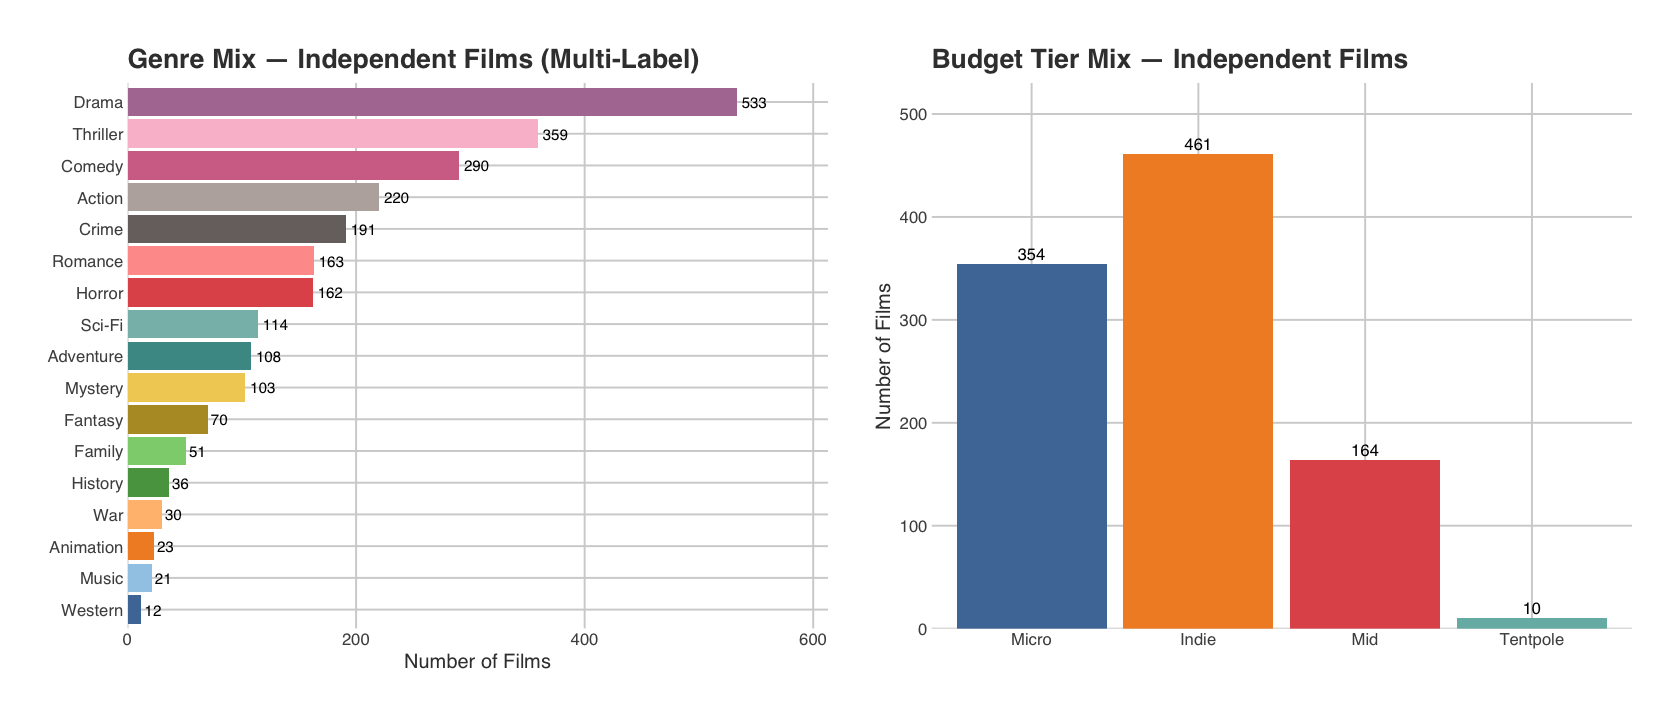

group,n,pct_micro,median_budget_m,median_roi,mean_roi,pct_loss
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Independent,989,35.8,15.2,0.21,2.19,44.5
Major Studio,2720,6.8,45.2,1.39,2.72,20.0


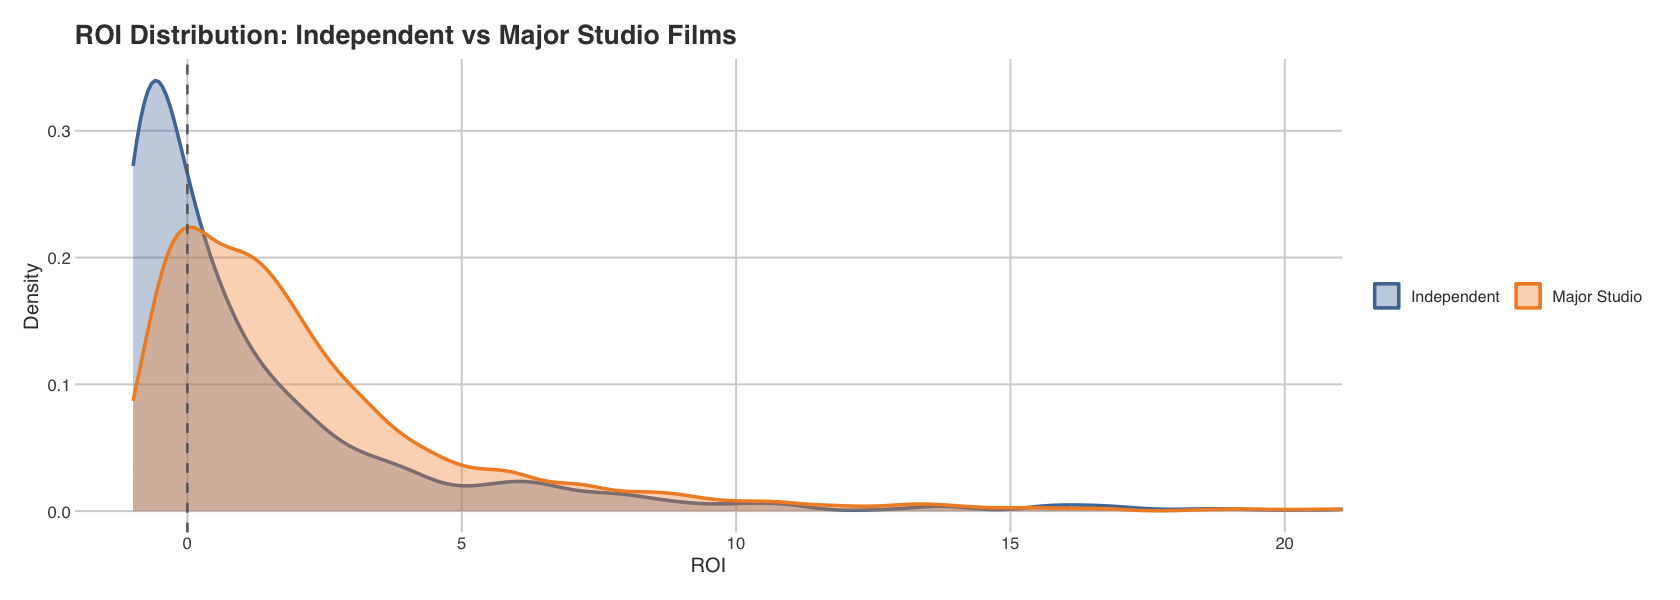

In [15]:
options(repr.plot.width = 14, repr.plot.height = 6)

df_indie  <- df %>% filter(studio_group == 'Independent')
df_major  <- df %>% filter(studio_group != 'Independent')
tier_levels   <- c('Micro', 'Indie', 'Mid', 'Tentpole', 'Mega')
season_levels <- c('Dump', 'Spring', 'Summer', 'Fall', 'Awards')
genre_cols    <- c('genre_action','genre_adventure','genre_animation','genre_comedy',
                   'genre_crime','genre_drama','genre_family','genre_fantasy',
                   'genre_history','genre_horror','genre_music','genre_mystery',
                   'genre_romance','genre_sci_fi','genre_thriller','genre_war','genre_western')
genre_labels  <- c('Action','Adventure','Animation','Comedy','Crime','Drama',
                   'Family','Fantasy','History','Horror','Music','Mystery',
                   'Romance','Sci-Fi','Thriller','War','Western')

cat('=== Independent films removed ===\n')
cat(sprintf('  Count: %d (%.1f%% of full dataset)\n',
            nrow(df_indie), 100 * nrow(df_indie) / nrow(df)))

# ── Genre distribution (multi-label) ──────────────────────────────────────────
p_genre <- purrr::map2_dfr(genre_cols, genre_labels, function(col, label) {
  tibble(genre = label, films = sum(df_indie[[col]]))
}) %>%
  filter(films > 0) %>%
  arrange(films) %>%
  mutate(genre = fct_inorder(genre)) %>%
  ggplot(aes(x = films, y = genre, fill = genre)) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = films), hjust = -0.2, size = 3.2) +
  scale_x_continuous(expand = expansion(mult = c(0, 0.15))) +
  scale_fill_tableau(palette = 'Tableau 20') +
  labs(title = 'Genre Mix — Independent Films (Multi-Label)',
       x = 'Number of Films', y = NULL)

# ── Budget tier distribution ──────────────────────────────────────────────────
p_tier <- df_indie %>%
  mutate(budget_tier = factor(budget_tier, levels = tier_levels)) %>%
  count(budget_tier, name = 'films') %>%
  ggplot(aes(x = budget_tier, y = films, fill = budget_tier)) +
  geom_col(show.legend = FALSE) +
  geom_text(aes(label = films), vjust = -0.4, size = 3.5) +
  scale_y_continuous(expand = expansion(mult = c(0, 0.15))) +
  scale_fill_tableau() +
  labs(title = 'Budget Tier Mix — Independent Films',
       x = NULL, y = 'Number of Films')

library(patchwork)
p_genre + p_tier

# ── ROI comparison: Independent vs Major ─────────────────────────────────────
options(repr.plot.width = 14, repr.plot.height = 5)

df %>%
  mutate(group = ifelse(studio_group == 'Independent', 'Independent', 'Major Studio')) %>%
  ggplot(aes(x = roi, fill = group, color = group)) +
  geom_density(alpha = 0.35, linewidth = 1) +
  geom_vline(xintercept = 0, linetype = 'dashed', color = 'grey40', linewidth = 0.7) +
  coord_cartesian(xlim = c(-1, 20)) +
  scale_fill_tableau() +
  scale_color_tableau() +
  labs(title = 'ROI Distribution: Independent vs Major Studio Films',
       x = 'ROI', y = 'Density', fill = NULL, color = NULL) +
  theme(legend.position = 'right')

# ── Summary table ─────────────────────────────────────────────────────────────
df %>%
  mutate(group = ifelse(studio_group == 'Independent', 'Independent', 'Major Studio')) %>%
  group_by(group) %>%
  summarise(
    n               = n(),
    pct_micro       = round(100 * mean(budget_tier == 'Micro'), 1),
    median_budget_m = round(median(budget_adj) / 1e6, 1),
    median_roi      = round(median(roi), 2),
    mean_roi        = round(mean(roi), 2),
    pct_loss        = round(100 * mean(roi < 0), 1),
    .groups = 'drop'
  )
